# Propósito do código × loop — `code_output.png` (Seção 4.2.5)

Mesmo gráfico de `graphic/code/grafico_tipo_codigo.ipynb`. Os números vêm das colunas *Code purpose* e *Code loop* de `../data/tabela_de_codigos_artefatos.csv`: barras por propósito do código, empilhadas por como o loop de revisão/reparo é fechado.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import dados_artefatos as da
from cores import LOOP

# caminho percorrido pelo código gerado: chave -> (rótulo da legenda, cor), na ordem de empilhamento
_codigo = {"direto": "CL2", "loop_llm": "CL1", "outro": "CL3", "loop_humano": "CL4", "so_humano": "CL6", "loop_duplo": "CL5"}
caminhos = {k: LOOP[c] for k, c in _codigo.items()}

In [2]:
# Estudos por propósito do código, separados pelo caminho percorrido
rotulos = {"CP1": "Unit testing", "CP2": "E2E testing", "CP3": "Bug reproduction\nand patch validation",
           "CP4": "Security/vulnerability", "CP5": "Acceptance testing", "CP6": "Mutation", "CP7": "API testing",
           "CP8": "Training data", "CP9": "Other (fuzz drivers,\ncompilers, amplification...)"}
tabela = da.cruzamento("Code purpose", "Code loop")
ordem = sorted([c for c in rotulos if c != "CP9"], key=lambda c: -tabela.loc[c].sum()) + ["CP9"]   # decrescente, "Other" no fim
dados = [{"tipo": rotulos[c], "segmentos": {k: int(tabela.loc[c, cod]) for k, cod in _codigo.items()}} for c in ordem]

x_pos = range(len(dados))
totais_cam = {k: sum(d["segmentos"][k] for d in dados) for k in caminhos}
total = sum(totais_cam.values())
print([sum(d["segmentos"].values()) for d in dados], totais_cam, "total =", total)
assert total == len(da.estudos("Code purpose"))

[139, 26, 18, 15, 12, 11, 8, 1, 45] {'direto': 91, 'loop_llm': 108, 'outro': 49, 'loop_humano': 10, 'so_humano': 16, 'loop_duplo': 1} total = 275


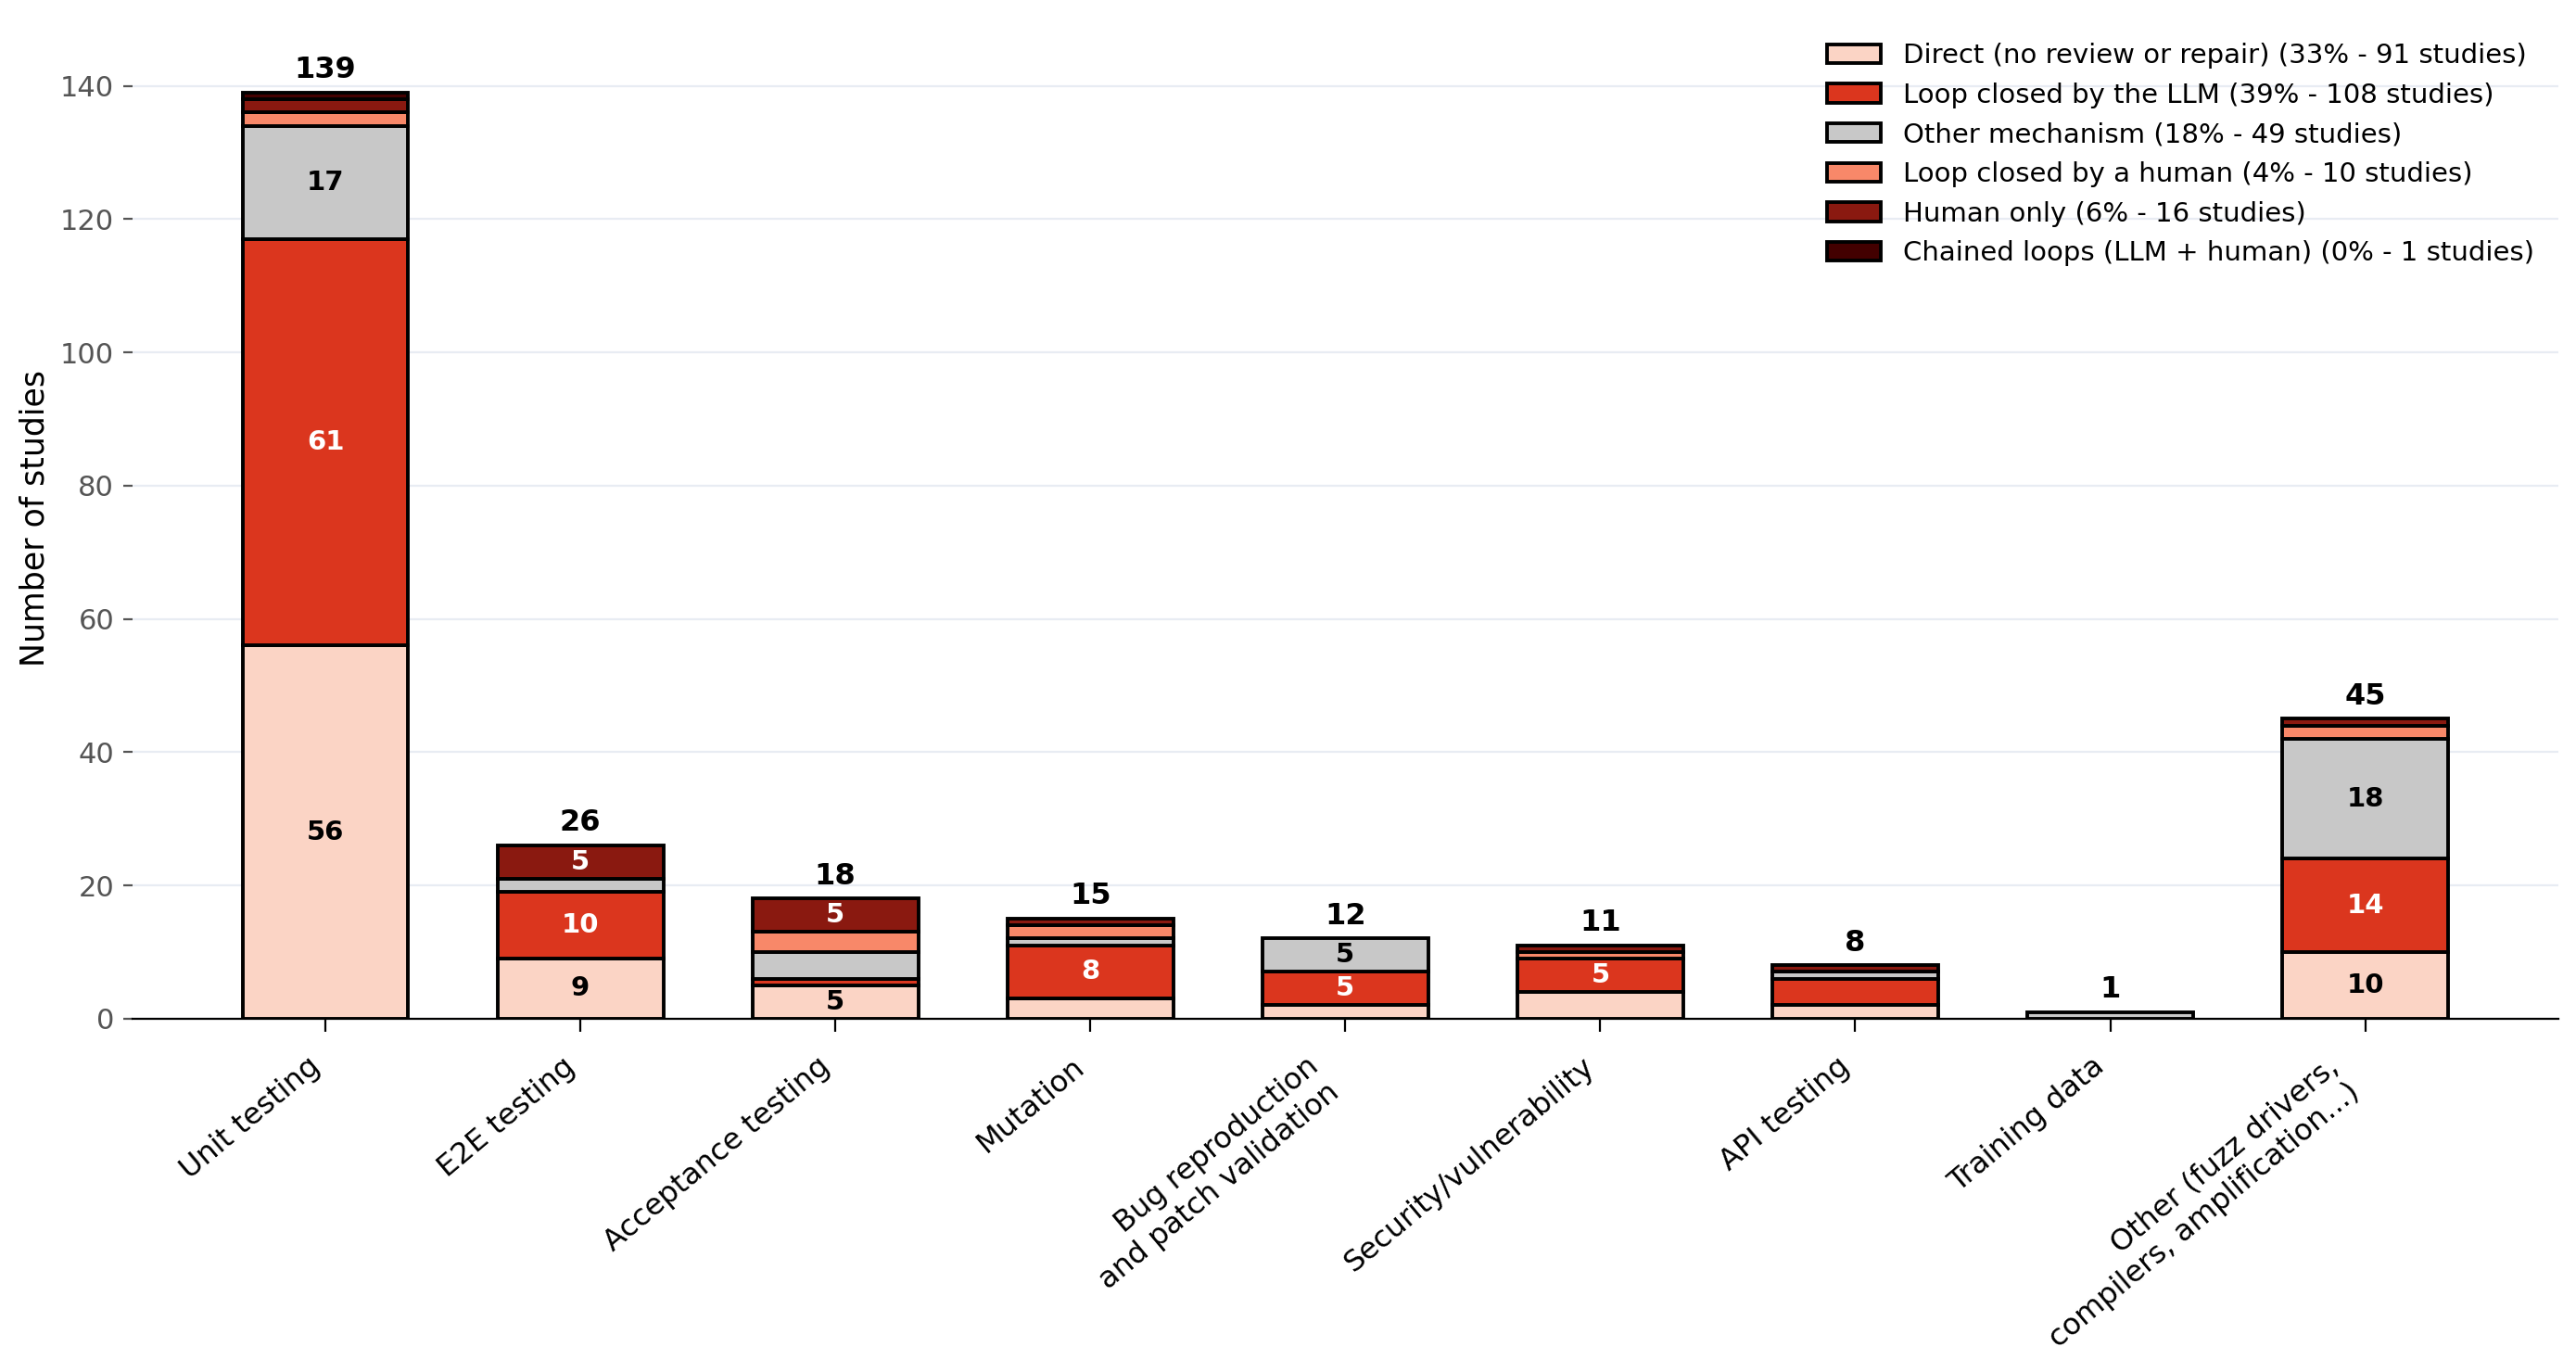

In [3]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

fig, ax = plt.subplots(figsize=(14, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for chave, (_, cor) in caminhos.items():   # empilha sempre na ordem da legenda
        v = d["segmentos"][chave]
        if v == 0:
            continue
        ax.bar(x, v, bottom=base, color=cor, width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe
        if v >= 5:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4)
        base += v
    ax.text(x, base + 1.2, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=40, ha="right", fontsize=11.5)

ax.set_ylim(0, max(sum(d["segmentos"].values()) for d in dados) * 1.08)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", linewidth=1.4,
          label=f"{nome} ({totais_cam[k] / total:.0%} - {totais_cam[k]} studies)")
    for k, (nome, cor) in caminhos.items()
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=10.5)

plt.tight_layout()
plt.savefig("code_output.png", bbox_inches="tight", dpi=200)
plt.savefig("code_output.pdf", bbox_inches="tight")
plt.show()